## 1. Environment Setup & Data Loading

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure correct path whether the working directory is repo root or notebooks/
data_path = 'data/creditcard.csv' if os.path.exists('data/creditcard.csv') else '../data/creditcard.csv'

# Load the dataset
df = pd.read_csv(data_path)

print(f"Dataset loaded successfully from: {data_path}")
print(f"Dataset dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns")

# Preview the first 5 records
df.head()

Dataset loaded successfully from: ../data/creditcard.csv
Dataset dimensions: 284,807 rows, 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Inspecting Data Types, Missing Values & Duplicates

In [2]:
# 1. Dataset information & memory usage
print("--- Dataset Info ---")
df.info()

# 2. Check for missing (null/NaN) values across all features
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percent.round(4)
})

missing_only = missing_df[missing_df['Missing Count'] > 0]

print("\n--- Missing Values Check ---")
if missing_only.empty:
    print("Result: No missing (NaN / null) values found in any column.")
else:
    print(f"Found {len(missing_only)} column(s) with missing values:")
    display(missing_only)

# 3. Check for duplicate rows
duplicates_count = df.duplicated().sum()
print(f"\n--- Duplicate Rows ---")
print(f"Duplicate rows detected: {duplicates_count:,} ({(duplicates_count / len(df) * 100):.2f}%)")

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

## 3. Masked Value Checks & Duplicate Analysis

In [3]:
# 1. Check for infinite values (np.inf, -np.inf)
inf_counts = np.isinf(df.select_dtypes(include=[np.number])).sum()
print("Infinite values per column (if any):")
print(inf_counts[inf_counts > 0] if (inf_counts > 0).any() else "No infinite values found.\n")

# 2. Check for invalid domain values (e.g., negative Amount or Time)
invalid_amounts = (df['Amount'] < 0).sum()
invalid_times = (df['Time'] < 0).sum()
print(f"Negative 'Amount' count: {invalid_amounts}")
print(f"Negative 'Time' count: {invalid_times}\n")

# 3. Analyze duplicate rows by Class distribution
duplicate_rows = df[df.duplicated(keep=False)]
print(f"Total rows involved in duplicates: {len(duplicate_rows):,}")
print("Class breakdown in duplicate rows:")
print(df[df.duplicated()]['Class'].value_counts().rename({0: 'Legitimate (0)', 1: 'Fraudulent (1)'}))

# 4. Remove duplicates (keeping the first occurrence) to prevent data leakage in training
df_cleaned = df.drop_duplicates(keep='first').copy()
print(f"\nShape before dropping duplicates: {df.shape}")
print(f"Shape after dropping duplicates:  {df_cleaned.shape}")

Infinite values per column (if any):
No infinite values found.

Negative 'Amount' count: 0
Negative 'Time' count: 0

Total rows involved in duplicates: 1,854
Class breakdown in duplicate rows:
Class
Legitimate (0)    1062
Fraudulent (1)      19
Name: count, dtype: int64

Shape before dropping duplicates: (284807, 31)
Shape after dropping duplicates:  (283726, 31)


## 4. Target Variable Analysis & Class Imbalance Quantification

--- Class Distribution Summary ---


,Count,Percentage (%)
Legitimate (Class 0),283253,99.8333
Fraudulent (Class 1),473,0.1667



Imbalance Ratio: Approximately 1 fraud case for every 598.8 legitimate transactions.


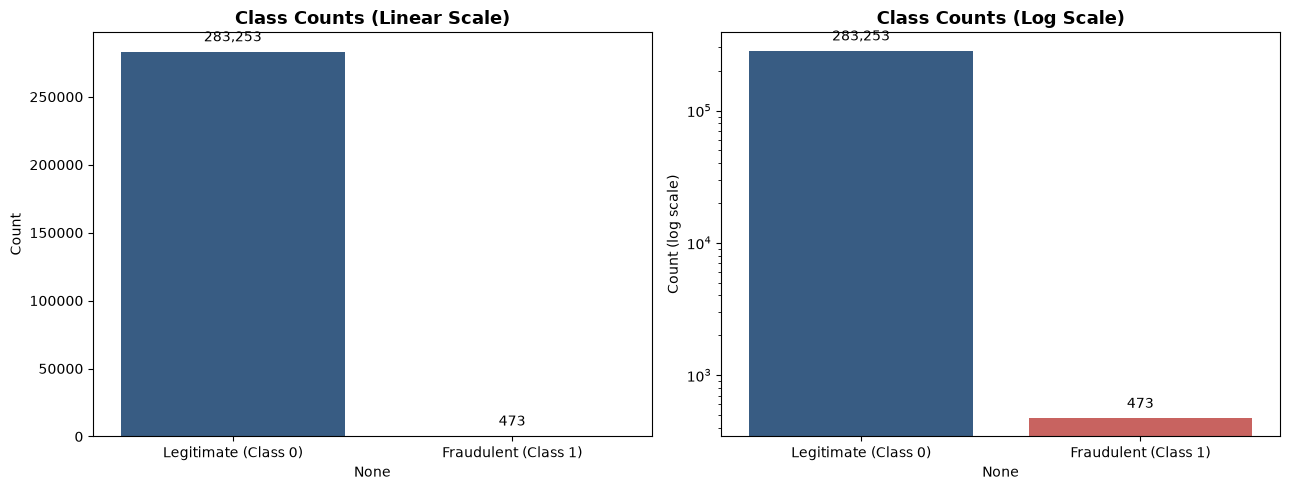

In [4]:
# 1. Target distribution counts and percentages
class_counts = df_cleaned['Class'].value_counts()
class_percentages = (df_cleaned['Class'].value_counts(normalize=True) * 100)

target_summary = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentages.round(4)
}, index=[0, 1]).rename(index={0: 'Legitimate (Class 0)', 1: 'Fraudulent (Class 1)'})

print("--- Class Distribution Summary ---")
display(target_summary)

imbalance_ratio = class_counts[0] / class_counts[1]
print(f"\nImbalance Ratio: Approximately 1 fraud case for every {imbalance_ratio:.1f} legitimate transactions.")

# 2. Visualizing the class distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Regular scale
sns.barplot(x=target_summary.index, y=target_summary['Count'], ax=axes[0], palette=['#2b5c8f', '#d9534f'], hue=target_summary.index, legend=False)
axes[0].set_title("Class Counts (Linear Scale)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 5), textcoords='offset points')

# Log scale to clearly show the minority class
sns.barplot(x=target_summary.index, y=target_summary['Count'], ax=axes[1], palette=['#2b5c8f', '#d9534f'], hue=target_summary.index, legend=False)
axes[1].set_yscale('log')
axes[1].set_title("Class Counts (Log Scale)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Count (log scale)")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 5. Statistical Breakdown & Distribution of Amount by Class

--- Transaction Amount ($) Statistics by Class ---


,Legitimate (Class 0),Fraudulent (Class 1)
count,283253.00,473.00
mean,88.41,123.87
std,250.38,260.21
min,0.00,0.00
25%,5.67,1.00
50%,22.00,9.82
75%,77.46,105.89
90%,203.00,348.65
95%,365.00,655.82
99%,1018.06,1364.14


C:\Users\Soham\AppData\Local\Temp\ipykernel_480\1213055041.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Legitimate (0)', 'Fraudulent (1)'])


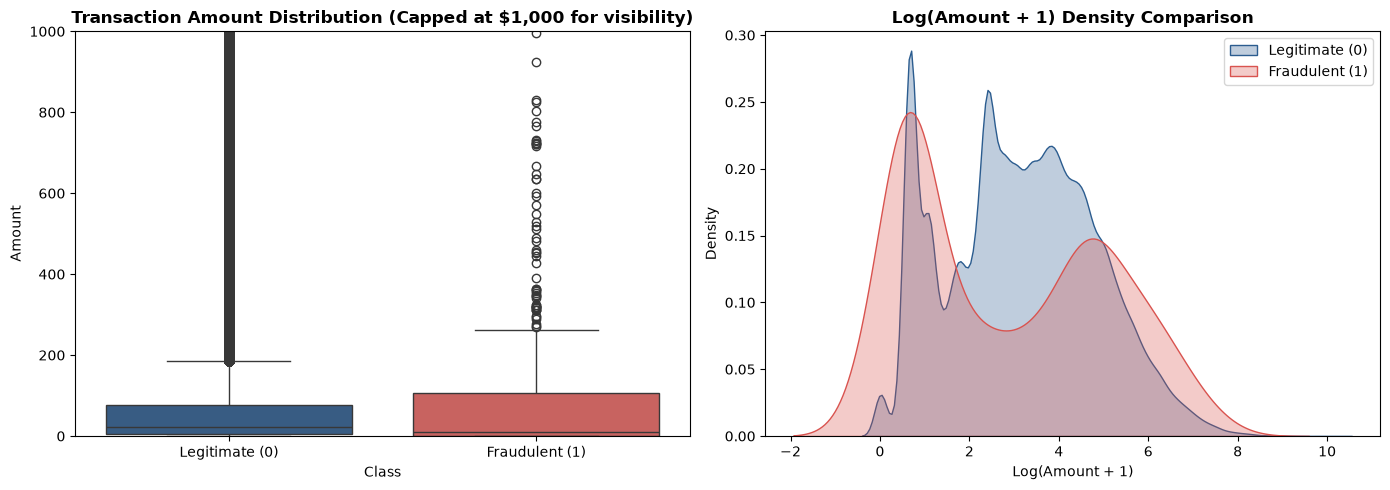

In [5]:
# 1. Descriptive statistics for Amount split by Class
legit_amt = df_cleaned[df_cleaned['Class'] == 0]['Amount']
fraud_amt = df_cleaned[df_cleaned['Class'] == 1]['Amount']

amt_stats = pd.DataFrame({
    'Legitimate (Class 0)': legit_amt.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]),
    'Fraudulent (Class 1)': fraud_amt.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
}).round(2)

print("--- Transaction Amount ($) Statistics by Class ---")
display(amt_stats)

# 2. Visual comparison of Amount distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot comparing amounts (with y-limit to avoid extreme outlier distortion)
sns.boxplot(x='Class', y='Amount', data=df_cleaned, ax=axes[0], palette=['#2b5c8f', '#d9534f'], hue='Class', legend=False)
axes[0].set_xticklabels(['Legitimate (0)', 'Fraudulent (1)'])
axes[0].set_title("Transaction Amount Distribution (Capped at $1,000 for visibility)", fontweight='bold')
axes[0].set_ylim(0, 1000)

# Log-transformed Amount density to inspect the true shapes without heavy skew
log_legit = np.log1p(legit_amt)
log_fraud = np.log1p(fraud_amt)

sns.kdeplot(log_legit, ax=axes[1], label='Legitimate (0)', color='#2b5c8f', fill=True, alpha=0.3)
sns.kdeplot(log_fraud, ax=axes[1], label='Fraudulent (1)', color='#d9534f', fill=True, alpha=0.3)
axes[1].set_title("Log(Amount + 1) Density Comparison", fontweight='bold')
axes[1].set_xlabel("Log(Amount + 1)")
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Temporal Analysis & Diurnal Cycles (`Time`)

Total timeframe covered: 48.0 hours (~2.0 days)


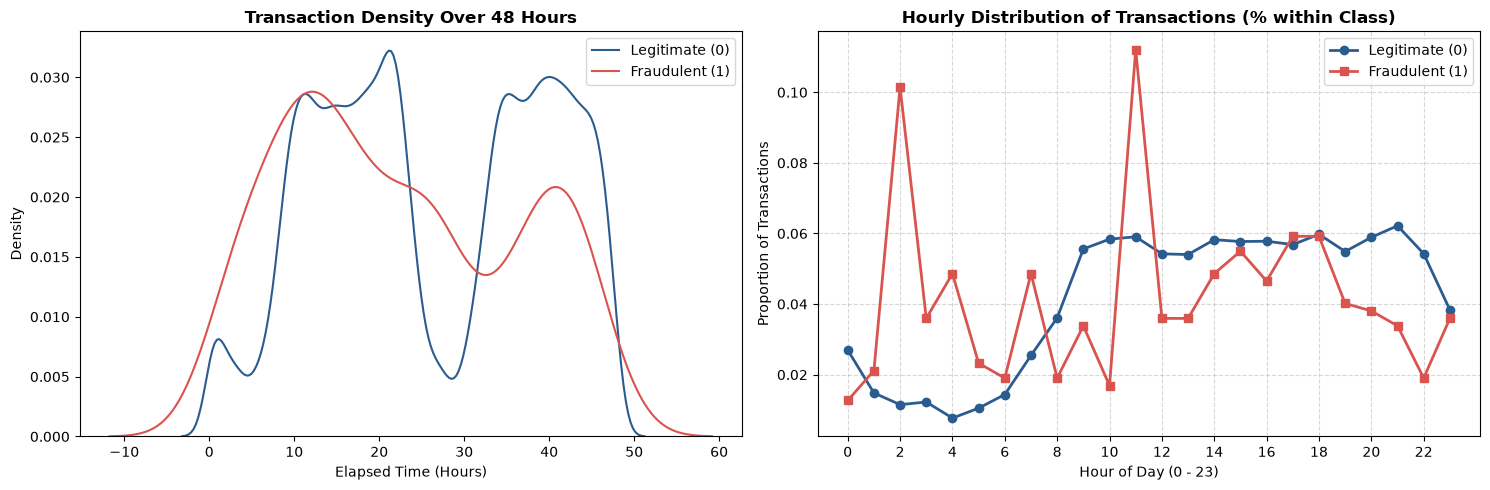

In [6]:
# 1. Total timeframe of the dataset
total_seconds = df_cleaned['Time'].max()
total_hours = total_seconds / 3600
print(f"Total timeframe covered: {total_hours:.1f} hours (~{total_hours / 24:.1f} days)")

# 2. Extract Hour of Day (0 to 23)
df_cleaned['Hour_of_Day'] = ((df_cleaned['Time'] / 3600) % 24).astype(int)

# 3. Plotting temporal distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Transaction density over the continuous 48-hour timeline
sns.kdeplot(df_cleaned[df_cleaned['Class'] == 0]['Time'] / 3600, ax=axes[0], label='Legitimate (0)', color='#2b5c8f', common_norm=False)
sns.kdeplot(df_cleaned[df_cleaned['Class'] == 1]['Time'] / 3600, ax=axes[0], label='Fraudulent (1)', color='#d9534f', common_norm=False)
axes[0].set_title("Transaction Density Over 48 Hours", fontweight='bold')
axes[0].set_xlabel("Elapsed Time (Hours)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Plot 2: Hourly pattern (0 to 23) normalized per class
hourly_legit = df_cleaned[df_cleaned['Class'] == 0]['Hour_of_Day'].value_counts(normalize=True).sort_index()
hourly_fraud = df_cleaned[df_cleaned['Class'] == 1]['Hour_of_Day'].value_counts(normalize=True).sort_index()

axes[1].plot(hourly_legit.index, hourly_legit.values, marker='o', label='Legitimate (0)', color='#2b5c8f', linewidth=2)
axes[1].plot(hourly_fraud.index, hourly_fraud.values, marker='s', label='Fraudulent (1)', color='#d9534f', linewidth=2)
axes[1].set_title("Hourly Distribution of Transactions (% within Class)", fontweight='bold')
axes[1].set_xlabel("Hour of Day (0 - 23)")
axes[1].set_ylabel("Proportion of Transactions")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Feature Correlation Analysis with `Class`

--- Top 5 Negatively Correlated Features with Fraud ---
V17       : -0.3135
V14       : -0.2934
V12       : -0.2507
V10       : -0.2070
V16       : -0.1872

--- Top 5 Positively Correlated Features with Fraud ---
V8        : +0.0331
V19       : +0.0336
V2        : +0.0846
V4        : +0.1293
V11       : +0.1491


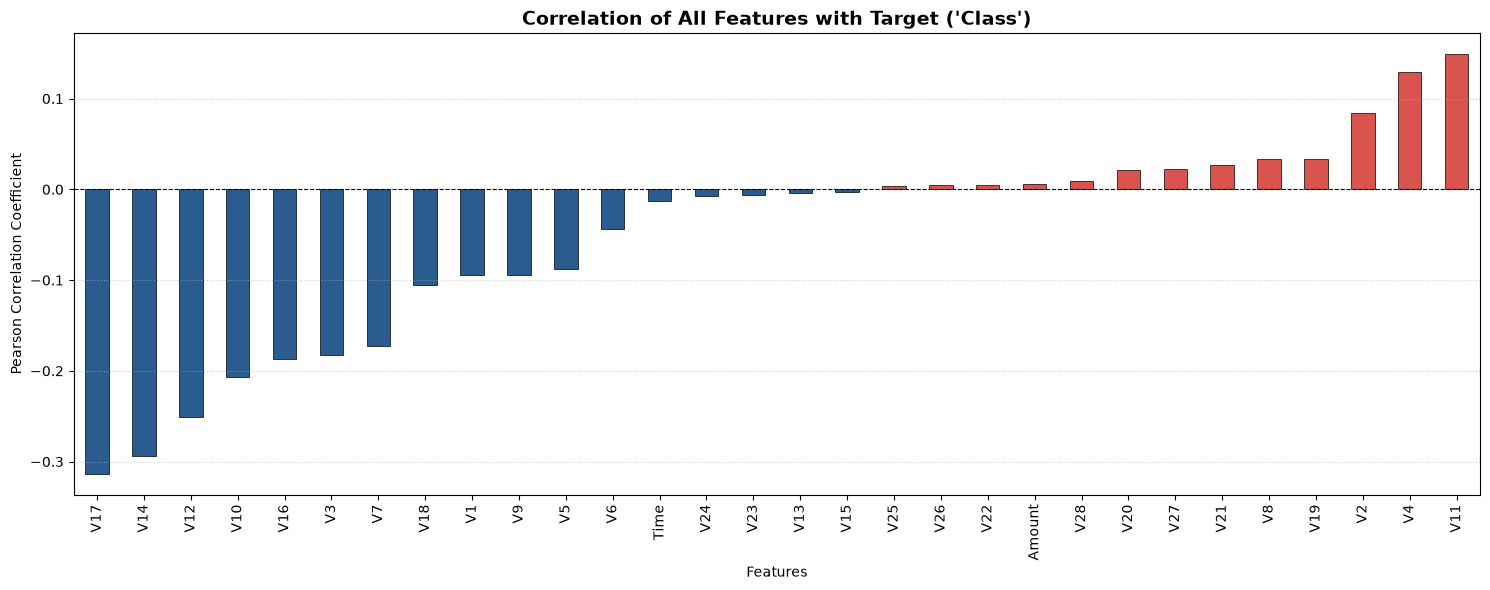

In [7]:
# 1. Compute Pearson correlation of all features with 'Class'
corr_series = df_cleaned.drop(columns=['Hour_of_Day']).corr()['Class'].drop('Class').sort_values()

# 2. Extract top positively and negatively correlated features
top_neg = corr_series.head(5)
top_pos = corr_series.tail(5)

print("--- Top 5 Negatively Correlated Features with Fraud ---")
for feat, val in top_neg.items():
    print(f"{feat:10s}: {val:+.4f}")

print("\n--- Top 5 Positively Correlated Features with Fraud ---")
for feat, val in top_pos.items():
    print(f"{feat:10s}: {val:+.4f}")

# 3. Bar plot of all feature correlations with Class
plt.figure(figsize=(15, 6))
colors = ['#d9534f' if val > 0 else '#2b5c8f' for val in corr_series.values]
corr_series.plot(kind='bar', color=colors, edgecolor='black', linewidth=0.5)

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title("Correlation of All Features with Target ('Class')", fontsize=14, fontweight='bold')
plt.xlabel("Features")
plt.ylabel("Pearson Correlation Coefficient")
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 8. Deep Dive into Top Discriminative Features & Outlier Analysis

C:\Users\Soham\AppData\Local\Temp\ipykernel_480\3604156354.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Legit (0)', 'Fraud (1)'])
C:\Users\Soham\AppData\Local\Temp\ipykernel_480\3604156354.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Legit (0)', 'Fraud (1)'])
C:\Users\Soham\AppData\Local\Temp\ipykernel_480\3604156354.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(['Legit (0)', 'Fraud (1)'])
C:\Users\Soham\AppData\Local\Temp\ipykernel_480\3604156354.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.

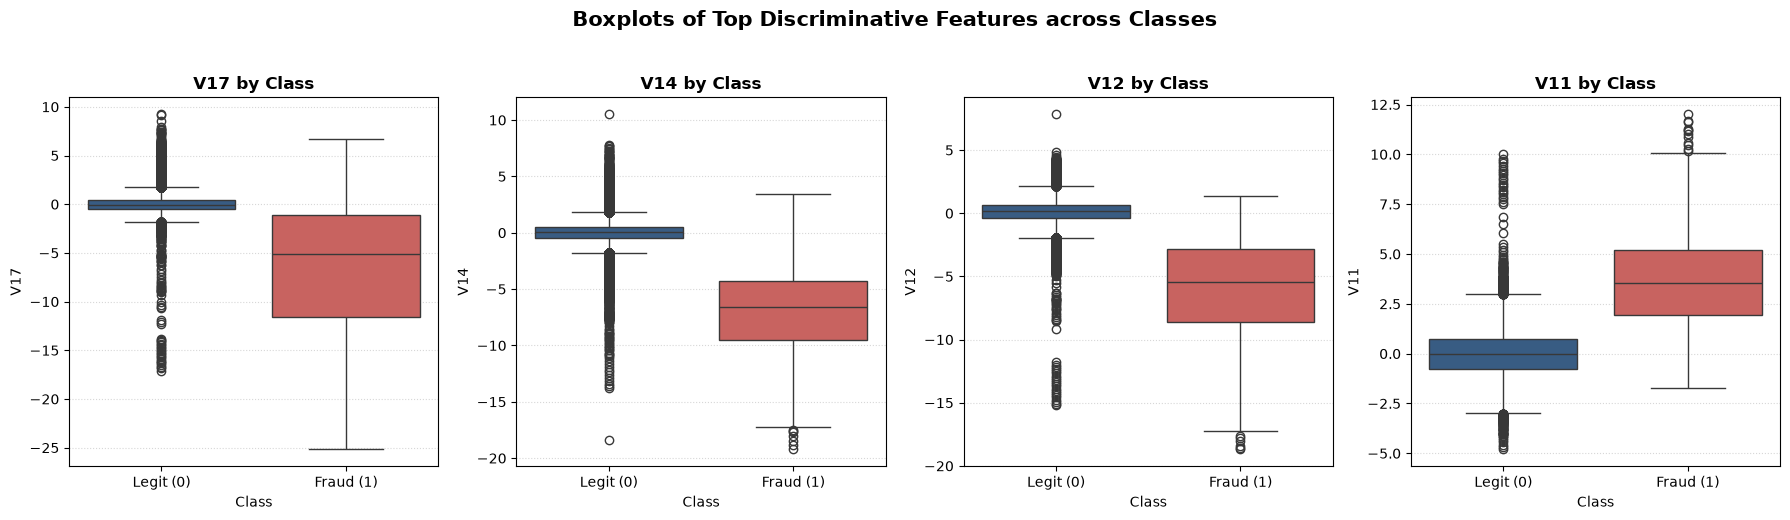

--- Median Separation for Top Features ---


,Legit Median,Fraud Median,Difference
V17,-0.065,-5.158,-5.093
V14,0.051,-6.591,-6.642
V12,0.141,-5.437,-5.578
V11,-0.034,3.526,3.560


In [8]:
top_features = ['V17', 'V14', 'V12', 'V11']

# 1. Compare feature distributions using Boxplots
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(top_features):
    sns.boxplot(
        x='Class', 
        y=col, 
        data=df_cleaned, 
        ax=axes[i], 
        palette=['#2b5c8f', '#d9534f'], 
        hue='Class', 
        legend=False
    )
    axes[i].set_title(f"{col} by Class", fontweight='bold')
    axes[i].set_xticklabels(['Legit (0)', 'Fraud (1)'])
    axes[i].grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle("Boxplots of Top Discriminative Features across Classes", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 2. Print median and IQR differences
summary_stats = {}
for col in top_features:
    legit_med = df_cleaned[df_cleaned['Class'] == 0][col].median()
    fraud_med = df_cleaned[df_cleaned['Class'] == 1][col].median()
    summary_stats[col] = {
        'Legit Median': round(legit_med, 3),
        'Fraud Median': round(fraud_med, 3),
        'Difference': round(fraud_med - legit_med, 3)
    }

print("--- Median Separation for Top Features ---")
display(pd.DataFrame(summary_stats).T)

## 9. Feature-Aware Preprocessing & Imputation Pipeline

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

# 1. Define feature groupings
pca_features = [f'V{i}' for i in range(1, 29)]
skewed_features = ['Amount', 'Time']

# 2. Build feature-specific transformers
# Skewed/outlier features: Median Imputer + RobustScaler (IQR-based)
skewed_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# PCA features: Mean Imputer (since PCA components are centered at 0)
pca_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean'))
])

# 3. Combine into a comprehensive ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('skewed', skewed_pipeline, skewed_features),
        ('pca', pca_pipeline, pca_features)
    ],
    remainder='drop'  # Exclude target 'Class' and auxiliary columns like 'Hour_of_Day'
)

print("Feature-aware preprocessing pipeline successfully configured:")
print(f" - Skewed numerical features ({len(skewed_features)}): Median Imputation + RobustScaler")
print(f" - PCA features ({len(pca_features)}): Mean Imputation + Passthrough")
preprocessor

Feature-aware preprocessing pipeline successfully configured:
 - Skewed numerical features (2): Median Imputation + RobustScaler
 - PCA features (28): Mean Imputation + Passthrough


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skewed', ...), ('pca', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_nam

## 10. Stratified Train/Test Split & Leak-Free Transformation

In [10]:
from sklearn.model_selection import train_test_split

# 1. Separate features and target
X = df_cleaned.drop(columns=['Class', 'Hour_of_Day'])
y = df_cleaned['Class']

# 2. Perform stratified split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

# Verify stratified proportions
print(f"Train set: {X_train.shape[0]:,} samples | Fraud count: {y_train.sum()} ({y_train.mean()*100:.3f}%)")
print(f"Test set:  {X_test.shape[0]:,} samples  | Fraud count: {y_test.sum()}  ({y_test.mean()*100:.3f}%)")

# 3. Fit pipeline on train set only, transform both train and test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 4. Convert back to clean DataFrames with readable column names
feature_names = [col.split('__')[-1] for col in preprocessor.get_feature_names_out()]

X_train_df = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_df = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print(f"\nSuccessfully transformed datasets:")
print(f" - X_train_df shape: {X_train_df.shape}")
print(f" - X_test_df shape:  {X_test_df.shape}")
print(f" - Null values remaining in train: {X_train_df.isnull().sum().sum()}")
print(f" - Null values remaining in test:  {X_test_df.isnull().sum().sum()}")

# Preview scaled features
X_train_df[['Amount', 'Time', 'V14', 'V17']].head()

Train set: 226,980 samples | Fraud count: 378 (0.167%)
Test set:  56,746 samples  | Fraud count: 95  (0.167%)

Successfully transformed datasets:
 - X_train_df shape: (226980, 30)
 - X_test_df shape:  (56746, 30)
 - Null values remaining in train: 0
 - Null values remaining in test:  0


,Amount,Time,V14,V17
226238,0.137472,0.701730,-0.313460,0.381516
134253,-0.209119,-0.048166,0.862657,-0.265345
186465,-0.098808,0.496931,-0.689465,0.793328
149493,-0.066242,0.076666,1.239627,-0.475182
18461,0.026608,-0.649581,-0.044638,0.787525


## 11. Export Preprocessed Train & Test Datasets

In [11]:
# 1. Resolve output directory
output_dir = 'data' if os.path.exists('data') else '../data'

# 2. Attach target label 'Class' to train and test sets
train_export = X_train_df.copy()
train_export['Class'] = y_train.values

test_export = X_test_df.copy()
test_export['Class'] = y_test.values

# 3. Export to CSV
train_file_path = os.path.join(output_dir, 'train_data.csv')
test_file_path = os.path.join(output_dir, 'test_data.csv')

train_export.to_csv(train_file_path, index=False)
test_export.to_csv(test_file_path, index=False)

# 4. Verification and file summaries
train_size_mb = os.path.getsize(train_file_path) / (1024 * 1024)
test_size_mb = os.path.getsize(test_file_path) / (1024 * 1024)

print("=" * 60)
print(" PREPROCESSED DATASETS SAVED SUCCESSFULLY")
print("=" * 60)
print(f" Train File: {train_file_path}")
print(f"   - Dimensions: {train_export.shape[0]:,} rows x {train_export.shape[1]} columns")
print(f"   - File Size:  {train_size_mb:.2f} MB")
print(f"   - Fraud:      {train_export['Class'].sum():,} ({train_export['Class'].mean()*100:.3f}%)\n")

print(f" Test File:  {test_file_path}")
print(f"   - Dimensions: {test_export.shape[0]:,} rows x {test_export.shape[1]} columns")
print(f"   - File Size:  {test_size_mb:.2f} MB")
print(f"   - Fraud:      {test_export['Class'].sum():,} ({test_export['Class'].mean()*100:.3f}%)")
print("=" * 60)

 PREPROCESSED DATASETS SAVED SUCCESSFULLY
 Train File: ../data\train_data.csv
   - Dimensions: 226,980 rows x 31 columns
   - File Size:  120.53 MB
   - Fraud:      378 (0.167%)

 Test File:  ../data\test_data.csv
   - Dimensions: 56,746 rows x 31 columns
   - File Size:  30.13 MB
   - Fraud:      95 (0.167%)
